# FENGSHA mineral dust emission in CECE

This notebook drives the **real C++ implementation** of the FENGSHA dust scheme
([cece_fengsha.cpp](../../src/core/physics/cece_fengsha.cpp)) from Python through
the `cece` pybind11 interface added in [bbakernoaa/CECE#13](https://github.com/bbakernoaa/CECE/pull/13).
There is no Python re-implementation of the physics: every number plotted here comes
out of the compiled scheme via `cece._cece_core`.

References:

- [CTSM5 Dust technical note - dust emission flux](https://escomp.github.io/CTSM/tech_note/Dust/CLM50_Tech_Note_Dust.html#dust-emission-flux)
- [docs/fengsha.md](../fengsha.md) - scheme fields, options, and the CTSM comment/references port
- [docs/notebooks](.) - this directory

**Prerequisite:** the extension module `build/src/python/cece/_cece_core*.so` must exist.
Configure and build CECE with `-DBUILD_PYTHON_BINDINGS=ON` (see the caveats cell at the
end). The bootstrap below looks for the built package relative to this notebook.


In [1]:
from pathlib import Path
import sys

# Walk up from the notebook directory looking for the staged python package.
here = Path.cwd()
for cand in [here, *here.parents]:
    pkg = cand / "build" / "src" / "python"
    if (pkg / "cece").is_dir() and any((pkg / "cece").glob("_cece_core*.so")):
        break
else:
    raise RuntimeError("CECE python bindings not found - build with -DBUILD_PYTHON_BINDINGS=ON (see final cell)")
sys.path.insert(0, str(pkg))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cece
import cece._cece_core as core

print("using extension:", pkg / "cece")
print("cece from:", cece.__file__)


using extension: /Users/barry/Documents/cece-devs/cecedust/build/src/python/cece
cece from: /Users/barry/Documents/cece-devs/cecedust/build/src/python/cece/__init__.py


## 1. The reviewed column contract

`describe_scheme` returns the *reviewed contract* that the column runtime enforces:
every required import (with canonical units), the optional imports, and the output
field(s). For dust schemes the size-bin extent of `fengsha_dust_emissions` is fixed
from the configured `particle_radii` / `bin_weights` (resolved through
`cece::dustbins::Resolve`, the configurable-bin machinery ported from the CTSM-derived
bin definitions).


In [2]:
KOK_YAML = """
particle_radii: [2.15e-6, 4.875e-6, 9.575e-6, 1.375e-4, 6.25e-4]
bin_lower_edges: [1.2e-6, 3.1e-6, 6.65e-6, 2.5e-5, 1.0e-4]
bin_upper_edges: [3.1e-6, 6.65e-6, 1.25e-4, 2.5e-4, 1.0e-3]
use_brittle_impaction: true
c_tune: 0.05
"""

desc = core.describe_scheme("fengsha", KOK_YAML, 1)
contract = pd.DataFrame(
    [(f.name, f.units, f.axis, f.extent, "required" if f.required else "optional", "yes" if f.output else "")
     for f in desc.fields],
    columns=["field", "units", "axis", "extent", "role", "output"],
)
contract


,field,units,axis,extent,role,output
0,friction_velocity,m s-1,surface,1,required,
1,threshold_velocity,m s-1,surface,1,required,
2,soil_moisture,1,surface,1,required,
3,clay_fraction,1,surface,1,required,
4,sand_fraction,1,surface,1,required,
5,silt_fraction,1,surface,1,required,
6,erodibility,1,surface,1,required,
7,drag_partition,1,surface,1,required,
8,air_density,kg m-3,surface,1,required,
9,lake_fraction,1,surface,1,required,


In [3]:
KOK = {
    "particle_radii": [2.15e-6, 4.875e-6, 9.575e-6, 1.375e-4, 6.25e-4],
    "bin_lower_edges": [1.2e-6, 3.1e-6, 6.65e-6, 2.5e-5, 1.0e-4],
    "bin_upper_edges": [3.1e-6, 6.65e-6, 1.25e-4, 2.5e-4, 1.0e-3],
    "use_brittle_impaction": True,
    "c_tune": 0.05,
}

def run_fengsha(field_values, options=KOK):
    # One Model step of the compiled C++ fengsha scheme.
    # field_values: dict name -> 1-D array of length ncol (canonical units);
    # returns the (ncol, nbin) emission array [kg m-2 s-1] and the xarray DataArray.
    n = len(next(iter(field_values.values())))
    grid = cece.Grid.columns([float(i) for i in range(n)], [0.0] * n)
    with cece.Model(["fengsha"], grid=grid, options={"fengsha": dict(options)}) as model:
        model.set_inputs({k: np.asarray(v, dtype=float).reshape(n, 1) for k, v in field_values.items()})
        out = model.step(time=0, dt=3600.0)
    da = out["fengsha_dust_emissions"]
    return np.asarray(da), da

def bare_soil(ncol, **overrides):
    # Default dusty-bare-soil column state; overrides are scalars broadcast per column.
    base = {
        "threshold_velocity": 0.15, "soil_moisture": 0.02, "clay_fraction": 0.10,
        "sand_fraction": 0.60, "silt_fraction": 0.30, "erodibility": 1.5, "drag_partition": 1.0,
        "air_density": 1.22, "lake_fraction": 0.0, "snow_fraction": 0.0, "land_mask": 1.0,
    }
    base.update(overrides)
    return {k: np.full(ncol, v) for k, v in base.items()}


## 2. Emission flux vs friction velocity

The CTSM dust note defines the size-resolved flux with a cubic dependence on the
friction velocity $u_* = \sqrt{C_D}\,\lvert u(z) \rvert$ and zero emission below
the saltation threshold $u_{*t}$; fine particles additionally feel an exponential
roll-off. Below we sweep $u_*$ across independent columns (one column per $u_*$
value) with a fixed threshold $u_{*t} = 0.15~\mathrm{m\,s^{-1}}$, and compare the
brittle-impaction switch (`use_brittle_impaction`, enabled by CTSM-style configs)
against the pure cubic response. See the Eq. (4)-(6) comments in
[cece_fengsha.cpp](../../src/core/physics/cece_fengsha.cpp).


[RANK:----] [INFO] fengsha: dust bins: Kok et al. (2014b) brittle-fragmentation weights integrated over the configured bins


Kokkos::OpenMP::initialize WARNING: OMP_PROC_BIND environment variable not set
  In general, for best performance with OpenMP 4.0 or better set OMP_PROC_BIND=spread and OMP_PLACES=threads
  For best performance with OpenMP 3.1 set OMP_PROC_BIND=true
  For unit testing set OMP_PROC_BIND=false



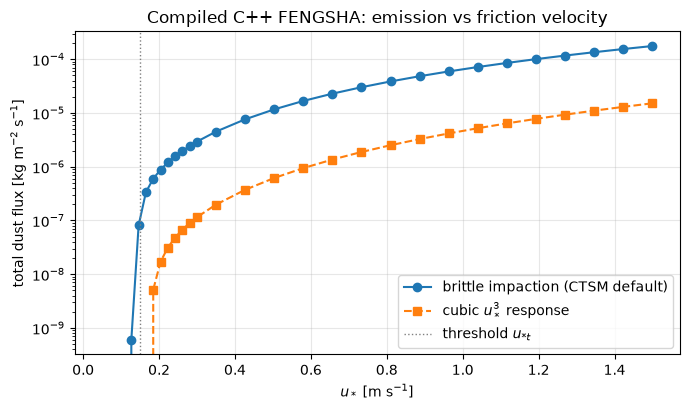

In [4]:
ustar = np.concatenate([np.linspace(0.05, 0.30, 14), np.linspace(0.35, 1.5, 16)])
inputs = bare_soil(ustar.size); inputs["friction_velocity"] = ustar

em_brittle, _ = run_fengsha(inputs, {**KOK, "use_brittle_impaction": True})
em_cubic, _ = run_fengsha(inputs, {**KOK, "use_brittle_impaction": False})
tot_b, tot_c = em_brittle.sum(axis=1), em_cubic.sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(ustar, tot_b, "o-", label="brittle impaction (CTSM default)")
ax.plot(ustar, tot_c, "s--", label="cubic $u_*^3$ response")
ax.axvline(0.15, color="grey", lw=1, ls=":", label="threshold $u_{*t}$")
ax.set_yscale("log"); ax.set_xlabel("$u_*$ [m s$^{-1}$]"); ax.set_ylabel("total dust flux [kg m$^{-2}$ s$^{-1}$]")
ax.set_title("Compiled C++ FENGSHA: emission vs friction velocity"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()


Zero flux below the threshold, then the steep $u_*^3$-type growth, with the brittle
term damping the near-threshold response - matching the comments added to the scheme
following the CTSM dust note.


## 3. Soil-moisture suppression

Moisture enters through the wetness factor $f(\omega)$ of FENGSHA Eq. (6)
(I23/I24; see [docs/fengsha.md](../fengsha.md)). With everything else fixed:


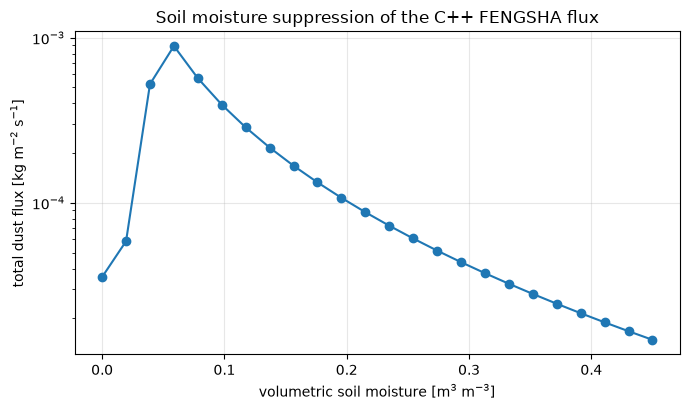

flux ratio dry/wet: 2.4


In [5]:
mois = np.linspace(0.0, 0.45, 24)
inputs = bare_soil(mois.size, friction_velocity=1.0); inputs["soil_moisture"] = mois
em, _ = run_fengsha(inputs)
tot = em.sum(axis=1)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(mois, tot, "o-")
ax.set_yscale("log"); ax.set_xlabel("volumetric soil moisture [m$^3$ m$^{-3}$]"); ax.set_ylabel("total dust flux [kg m$^{-2}$ s$^{-1}$]")
ax.set_title("Soil moisture suppression of the C++ FENGSHA flux"); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

print(f"flux ratio dry/wet: {tot[0] / tot[-1]:.3g}")


## 4. Size-resolved flux and configurable bins

Dust is emitted per size bin. The bin set is *configuration*, not a hardcoded 5:
`particle_radii` (optionally with `bin_lower_edges` / `bin_upper_edges`) or
`bin_weights` fix the size dimension of `fengsha_dust_emissions`. Here we run the
Kok et al. (2002) five-bin geometry used by CTSM's dust bins and show the per-bin shares.


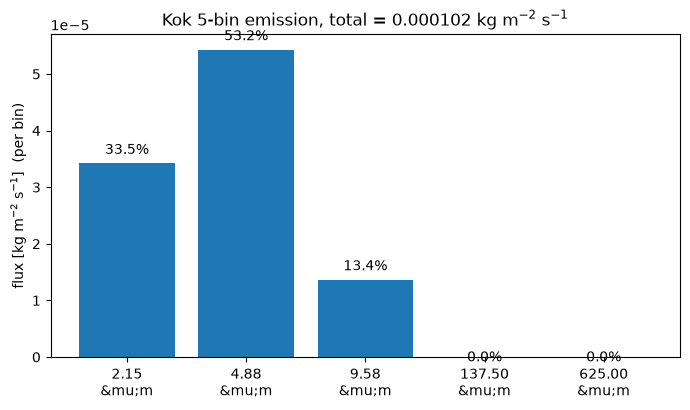

<xarray.DataArray 'fengsha_dust_emissions' (column: 1, size: 5)> Size: 40B
array([[3.41999120e-05, 5.42956878e-05, 1.36478170e-05, 0.00000000e+00,
        0.00000000e+00]])
Coordinates:
  * column     (column) int64 8B 0
    longitude  (column) float64 8B 0.0
    latitude   (column) float64 8B 0.0
Dimensions without coordinates: size
Attributes:
    units:    kg m-2 s-1

In [6]:
inputs = bare_soil(1, friction_velocity=1.2)
em5, da5 = run_fengsha(inputs)

r5 = np.array(KOK["particle_radii"])
shares = em5[0] / em5[0].sum()

fig, ax = plt.subplots(figsize=(7, 4.2))
x = np.arange(len(r5))
ax.bar(x, em5[0], color="tab:blue")
for i, (v, s) in enumerate(zip(em5[0], shares)):
    ax.annotate(f"{s*100:.1f}%", (i, v), ha="center", va="bottom" if v > 0 else "top",
                xytext=(i, v + max(em5[0]) * 0.02))
ax.set_xticks(x); ax.set_xticklabels([f"{rr*1e6:.2f}\n&mu;m" for rr in r5])
ax.set_ylabel("flux [kg m$^{-2}$ s$^{-1}$]  (per bin)")
ax.set_title(f"Kok 5-bin emission, total = {em5[0].sum():.3g} kg m$^{{-2}}$ s$^{{-1}}$")
fig.tight_layout(); plt.show()
da5


The two coarsest bins (137.5 um and 625 um radii) receive essentially no emission
here because of the exponential roll-off of the emission efficiency with diameter -
the $\exp(-(d/\lambda)^3)$-style cutoff discussed in the CTSM note.


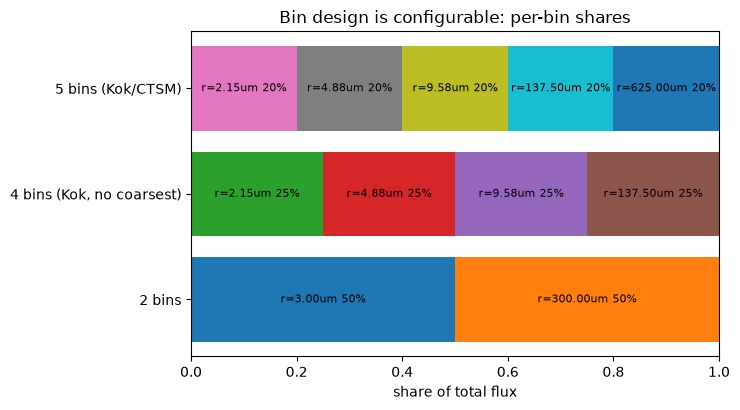

,configuration,n_bin,total flux [kg m-2 s-1]
0,2 bins,2,0.000102
1,"4 bins (Kok, no coarsest)",4,0.000102
2,5 bins (Kok/CTSM),5,0.000102


In [7]:
bins_sets = {
    "2 bins": [3.0e-6, 3.0e-4],
    "4 bins (Kok, no coarsest)": [2.15e-6, 4.875e-6, 9.575e-6, 1.375e-4],
    "5 bins (Kok/CTSM)": list(KOK["particle_radii"]),
}

fig, ax = plt.subplots(figsize=(7.5, 4.2))
rows = []
for k, (label, radii) in enumerate(bins_sets.items()):
    opts = {k: v for k, v in {**KOK, "particle_radii": radii}.items() if "edges" not in k}
    em, _ = run_fengsha(bare_soil(1, friction_velocity=1.2), opts)
    sh = em[0] / em[0].sum()
    left = 0.0
    for j, s in enumerate(sh):
        ax.barh(k, s, left=left)
        if s > 0.05:
            ax.text(left + s / 2, k, f"r={radii[j]*1e6:.2f}um {s*100:.0f}%", ha="center", va="center", fontsize=8)
        left += s
    rows.append([label, len(radii), float(em[0].sum())])

ax.set_yticks(range(len(bins_sets))); ax.set_yticklabels([r[0] for r in rows]); ax.set_xlim(0, 1); ax.set_xlabel("share of total flux")
ax.set_title("Bin design is configurable: per-bin shares")
fig.tight_layout(); plt.show()

pd.DataFrame(rows, columns=["configuration", "n_bin", "total flux [kg m-2 s-1]"])


The total flux changes with the bin set because thresholds and efficiencies are
evaluated on the configured radii - the bin geometry is a modelling choice, which is
exactly why CECE keeps it in the scheme options instead of hardcoding CTSM's five bins.


## 5. Configuration guardrails

The configurable-bin resolver rejects retired settings and tells column runners what a
size dimension needs:


In [8]:
for opts, why in [
    ("particle_radii: [2.15, 4.875, 9.575]\n", "radii given in micrometres -> rejected as a unit mistake (> 1e-3 m)"),
    ("num_bins: 5\n", "the retired fixed-count key"),
    ("use_brittle_impaction: true\n", "no radii/weights -> size extent under-determined"),
]:
    try:
        core.describe_scheme("fengsha", opts, 1)
        print(why, "-> accepted (unexpected)")
    except Exception as exc:
        print(f"{why}:\n  {exc}\n")


radii given in micrometres -> rejected as a unit mistake (> 1e-3 m):
  dust bins: 'particle_radii' contains 2.150000, which is not a plausible bin radius in metres - give radii/edges in m (1 um = 1.0e-6 m)

Recovery Suggestions:
  1. Check that the configuration file is valid YAML
  2. Verify all required fields are present in the configuration
  3. Call config.validate() to check for errors before initializing

the retired fixed-count key:
  fengsha: dust bins: the 'num_bins' option was removed - the bin count comes from the size dimension of the emission field. Configure the bin geometry instead with 'particle_radii', 'bin_lower_edges' and 'bin_upper_edges'.

Recovery Suggestions:
  1. Check that the configuration file is valid YAML
  2. Verify all required fields are present in the configuration
  3. Call config.validate() to check for errors before initializing

no radii/weights -> size extent under-determined:
  fengsha: column execution needs a fixed size-bin count - configure 'p

## Caveats & reproducibility

- This notebook executes the **compiled scheme**, so it only runs where
  `_cece_core` has been built. Minimal recipe:

  ```console
  cmake -B build -DCMAKE_BUILD_TYPE=Release -DBUILD_PYTHON_BINDINGS=ON         -DCECE_BUILD_TESTING=OFF -DENABLE_ESMF=OFF
  cmake --build build --target _cece_core -j 8
  ```

  then run the notebook from `docs/notebooks/`. On some machines the CMake configure
  needs OpenMP hints (e.g. Homebrew `libomp`) or a pinned `Kokkos_DIR`; those details
  stay out-of-repo on purpose - the notebook itself only needs the staged package.
- The high-level API here is `cece.Model` (numpy or labeled xarray inputs with units);
  the lower-level `core.SchemeRuntime` behind `describe_scheme` offers the same
  physics with explicit Fortran-ordered `(ncol, extent)` arrays.
- Physics fidelity checks live in the property tests
  ([tests/test_fengsha_properties.cpp](../../tests/test_fengsha_properties.cpp));
  this notebook is illustrative, not a test.
